# deliberation allocation: Methods and evidence

**Level:** 1 **Prerequisites:** 03-sequential-control **Reading time:** 15 minutes

**Question:** What does the frozen C13 evidence show about planner decisions, delegation and measured delay?

## Objectives

This lesson investigates the question: What does the frozen C13 evidence show about planner decisions, delegation and measured delay?

## Setup

The versions below are pinned in `notebooks/requirements.txt` and are also recorded in this notebook's metadata;

```bash
pip install reflexmesh==0.1.2 numpy==2.5.3 matplotlib==3.11.2 torch==2.14.1 joblib==1.6.0 gymnasium==1.4.0 scikit-learn==1.9.1 stable-baselines3==2.9.2 sb3-contrib==2.9.2
```

In [1]:
# Import the released policy API and the pinned plotting/runtime dependencies.
import hashlib
import importlib.metadata
import json
import os
from io import BytesIO
from pathlib import Path
import matplotlib.pyplot as plt
from IPython.display import Image, display
from reflexmesh.environments import CaseSpec
from reflexmesh.evaluation.runner import aggregate, run_episode
from reflexmesh.pipeline import make_policy
from reflexmesh.planners import OllamaPlanner

for distribution in ("reflexmesh", "numpy", "matplotlib"):
    print(f"{distribution}=={importlib.metadata.version(distribution)}")
import sys
ROOT = Path('../../../').resolve()
sys.path.insert(0, str(ROOT))
checkpoint_dir = Path(os.environ.get('NEURAXIS_CHECKPOINTS', str(ROOT / 'models/checkpoints')))
planner_model = os.environ.get('NEURAXIS_NOTEBOOK_MODEL')
planner = OllamaPlanner(planner_model) if planner_model else None
sys.path.insert(0, str(ROOT / 'notebooks'))

reflexmesh==0.1.2
numpy==2.5.3
matplotlib==3.11.2


## Data
The notebook reads committed product artifacts. Owner: Neuraxis. Repository: https://github.com/fsantibanezleal/CAOS_Neuraxis. License: Apache-2.0. The JSON is a first-party, frozen experiment artifact; no external benchmark data are redistributed in this notebook;

This notebook reads `data/derived/index.json` and the listed trace artifacts. The method run uses an isolated Reflexmesh case workspace; For learned methods, fetch the exact public release assets with `python -m reflexmesh.Cli fetch-models --destination models/checkpoints --version v0.01.000`, then set `NEURAXIS_CHECKPOINTS` to that folder; The release manifest verifies asset hashes. Planner methods M09/M10 are read from frozen traces unless `NEURAXIS_NOTEBOOK_MODEL` explicitly names a configured local Ollama model;

Artifacts for this lesson:

- `data/derived/index.json` - `data/derived/semantic-routing-study/analysis; - `data/derived/episodes/M11-C13-nominal-40000 - `data/derived/episodes/M12-C13-nominal-40000 - `data/derived/episodes/M09-C13-nominal-40000 - `data/derived/episodes/M10-C13-nominal-40000json`

## Method

Separate a fast policy decision from an optional planner call. Delegation is useful only when the change in independently verified outcome pays for planner delay, invalid proposals and unused work under the same observed candidate state.

### Formal quantity

A planner call is useful only when its expected change to verified utility pays for its latency and failure risk. The decision should compare incremental utility with cost on the same observed candidate set. The threshold is a policy choice to measure, not a biological constant or a guarantee of improvement.

$$ \Delta U(x)=\mathbb{E}[U_{\mathrm{delegate}}-U_{\mathrm{fast}}\mid x]-\lambda\,\mathbb{E}[T_{\mathrm{delegate}}\mid x] $$

### Reading this case

C13 makes planner time part of the task: a proposal that arrives after the deadline can be worse than a fast admissible action. Read the request, response, validation and effect events separately. A planner response can be syntactically valid yet stale, inadmissible or unused; none should count as a successful handoff. The matched fresh executions use one nominal seed, whereas the indexed plot spans the declared variants and seeds. M11's gate and M12's integrated policy are not interchangeable: one estimates whether to defer, while the other also carries resource and outcome state. Inspect the frozen result and controller cost together. If the fast controller already solves the case, a slower proposal does not demonstrate value unless it changes a consequential outcome under a controlled perturbation. The threshold must be evaluated on held-out conditions, not chosen after viewing the plotted test outcomes.

### Interpreting the evidence

The plot should be read as a cost-sensitive controller comparison, not as a count of language-model calls alone. A handoff can fail before a model is invoked, return malformed output, be rejected by the authority layer, finish too late or produce an unused suggestion. These outcomes have different operational costs and must remain separately recorded. The current case slice makes deadline pressure explicit, but a one-seed fresh execution cannot estimate the probability of useful delegation. The frozen variant series is still limited to the declared C13 simulator and its specific planner behavior. A stronger allocation study would pair fast-only and delegated executions from the same observation, cap the reasoner's budget, randomize model latency and failure independently of task difficulty, and evaluate on task compositions withheld from gate fitting. The expected-utility equation clarifies the tradeoff; it does not validate the gate's labels or threshold. In this repository the fitted gate's never-defer behavior and M12's lower completion are negative findings that should remain visible when a reader interprets this introductory example.

### Adapt the experiment

To adapt this exercise, use a deterministic planner stub first and vary response delay, invalid output and deadline independently. Pair delegated and fast-only actions from identical candidate sets; keep the model's response out of the task oracle. Fit the threshold on one set and freeze it before held-out evaluation. Report requests, accepted proposals, late responses, rejected actions, unused work, task outcomes and added latency as separate fields.

### deliberation allocation · level 1 | Verify the audit and each trace's bytes before interpreting outcomes.

In [2]:
# Load manifest-verified evidence and keep failures in every denominator.
import sys
sys.path.insert(0, str(ROOT / 'notebooks'))
from lesson_support import load_lesson_evidence
selected_methods = trace_methods = ['M11', 'M12']
sample_case, seed = 'C13', 40000
evidence = load_lesson_evidence(
    ROOT, topic='04-deliberation-allocation', methods=tuple(trace_methods),
    sample_case=sample_case, seed=seed,
    include_core=False, include_transfer=False,
)
index, audit = evidence['index'], evidence['audit']
records, case_records = evidence['records'], evidence['case_records']
print('Hash-verified records:', len(records), '| case variants:', len(case_records))


Hash-verified records: 2 | case variants: 12


### Inspect one guarded trace: deliberation allocation

C13 makes handoff allocation observable:

The example makes the proposed handoff path inspectable: identify the gate input, whether a planner is called, and which verified outcome follows. A request for more computation is not evidence that the extra computation helped. Record the delay and the terminal result separately, and keep the policy's action preference distinct from the runtime's authorization decision. The single case is a mechanics check, not a test of whether the gate learned when to defer.

### deliberation allocation · L1 | Build the first executable policy

In level 1, construct policy M11 for deliberation allocation with the public factory and keep its observation contract unchanged before sampling C13.


In [3]:
# Construct the first released policy through the public factory.
primary_id = 'M11'
primary_policy = make_policy(primary_id, checkpoint_dir, planner=planner)
print("Primary policy:", primary_id)


Primary policy: M11


### deliberation allocation · L1 | Execute the primary method on the named case

At level 1, the deliberation allocation evaluator runs M11 on C13 and derives success from the independent task postcondition, not from a replayed trace.


In [4]:
# Run the policy and verify the case postcondition independently.
primary_result = run_episode(primary_policy, CaseSpec(sample_case, "nominal", seed))
print("Primary task success:", primary_result["metrics"]["task_success"])


Primary task success: 1


### deliberation allocation · L1 | Construct an independent comparison policy

For level 1 of deliberation allocation, create M12 as a fresh object so recurrent state from M11 cannot leak into the matched comparison.


In [5]:
# Create a fresh policy object for the matched comparison.
secondary_id = 'M12'
secondary_policy = make_policy(secondary_id, checkpoint_dir, planner=planner)
print("Comparison policy:", secondary_id)


Comparison policy: M12


### deliberation allocation · L1 | Run the comparison under identical conditions

This level 1 comparison runs M12 on the same C13, nominal variant and seed, and it illustrates behavior rather than estimating a population rate.


In [6]:
# Use the same case, variant and seed for the second policy.
secondary_result = run_episode(secondary_policy, CaseSpec(sample_case, "nominal", seed))
print("Comparison task success:", secondary_result["metrics"]["task_success"])


Comparison task success: 1


### deliberation allocation · L1 | Aggregate the two executed episodes

At level 1, the package aggregator summarizes two executed deliberation allocation episodes, and cross-family claims still require the complete benchmark below.


In [7]:
# Aggregate executed outcomes with the package's descriptive evaluator.
fresh_runs = {primary_id: primary_result, secondary_id: secondary_result}
fresh_summary = aggregate([primary_result, secondary_result])
print("Fresh policy runs:", len(fresh_runs))
print("Fresh successes:", sum(run["metrics"]["task_success"] for run in fresh_runs.values()))


Fresh policy runs: 2
Fresh successes: 2


This level-01 bounded planner delegation panel aggregates each indexed variant after the preceding matched-run summary.


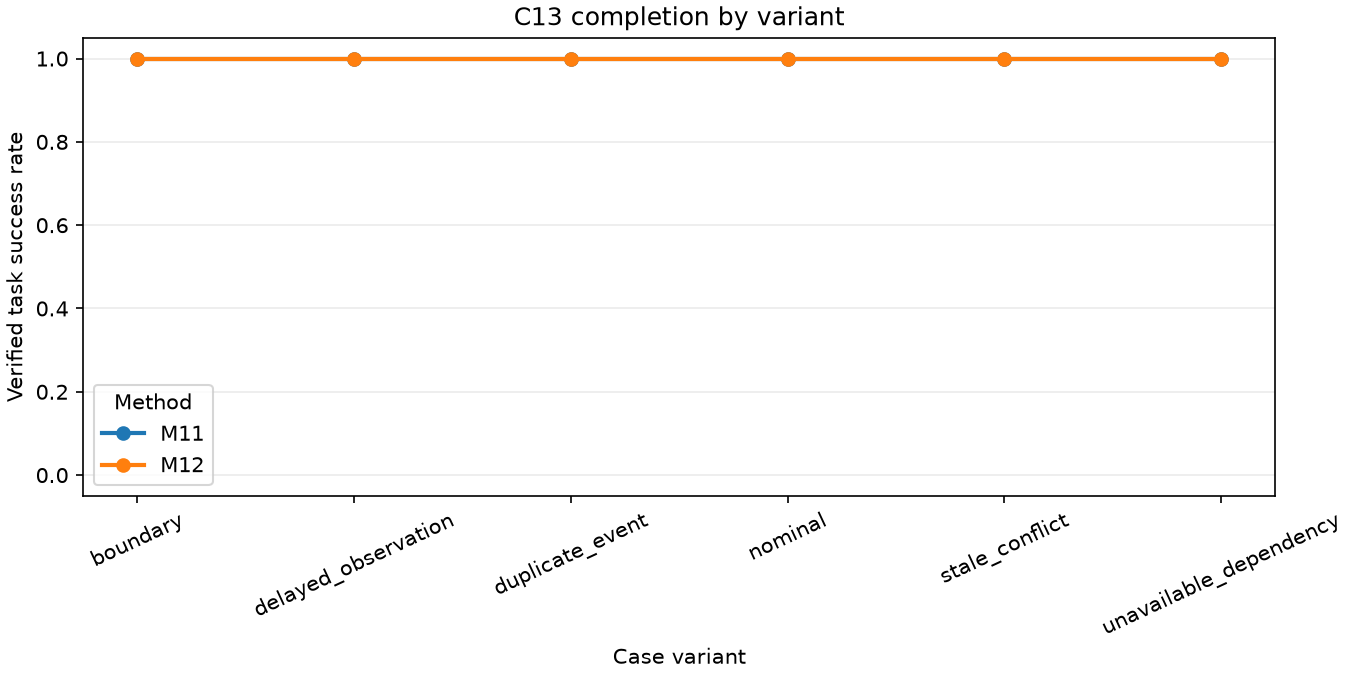

In [8]:
# Compare verified completion rates over every seed in each case variant.
methods_to_plot = selected_methods
variants = sorted({variant for _, variant in case_records})
fig, ax = plt.subplots(figsize=(9, 4.5), constrained_layout=True)
for method_id in methods_to_plot:
    rates = []
    for variant in variants:
        episodes = case_records.get((method_id, variant), [])
        rate = sum(bool(e['metrics']['task_success']) for e in episodes) / len(episodes) if episodes else float('nan')
        rates.append(rate)
    ax.plot(variants, rates, marker='o', linewidth=2, label=method_id)
ax.set_ylim(-0.05, 1.05)
ax.set_ylabel("Verified task success rate")
ax.set_xlabel("Case variant")
ax.set_title(sample_case + " completion by variant")
ax.tick_params(axis='x', rotation=25)
ax.grid(axis='y', alpha=.25)
ax.legend(title='Método' if False else 'Method')
image_buffer = BytesIO()
fig.savefig(image_buffer, format='png', dpi=150)
display(Image(data=image_buffer.getvalue()))
image_buffer.close()
plt.close(fig)




Chart 1, lesson level 1, summarizes family-level task completion for M01 and M12 for C13 in the planner delegation cost and paired task outcomes study. For chart 1 at level 1, the planner delegation cost and paired task outcomes denominator is the manifest-hash-verified C13 episode slice loaded above, and failed outcomes remain included. The designed C13 cases in chart 1 at level 1 for planner delegation cost and paired task outcomes cannot estimate real-world incident rates or performance on unseen software. Read chart 1 at level 1 alongside the planner delegation cost and paired task outcomes trace and verified postcondition before attributing an improvement to a controller.




Chart 1, lesson level 1, summarizes family-level task completion for M01 and M12 for C13 in the planner delegation cost and paired task outcomes study. The designed C13 cases in chart 1 at level 1 for planner delegation cost and paired task outcomes cannot estimate real-world incident rates or performance on unseen software. Read chart 1 at level 1 alongside the planner delegation cost and paired task outcomes trace and verified postcondition before attributing an improvement to a controller.

For deliberation allocation, the level-1 plot reads hash-verified task-postcondition outcomes for M11 and M12 across indexed C13 variants; For C13, a delegation request without a timely verified effect remains a failure in the level-1 denominator. This designed deliberation allocation family is not a confidence interval or evidence of generalization to other software tasks.

### deliberation allocation · L1 | Controller latency by variant

The level-1 deliberation allocation panel links the archived outcome slice to the separate matched execution above;


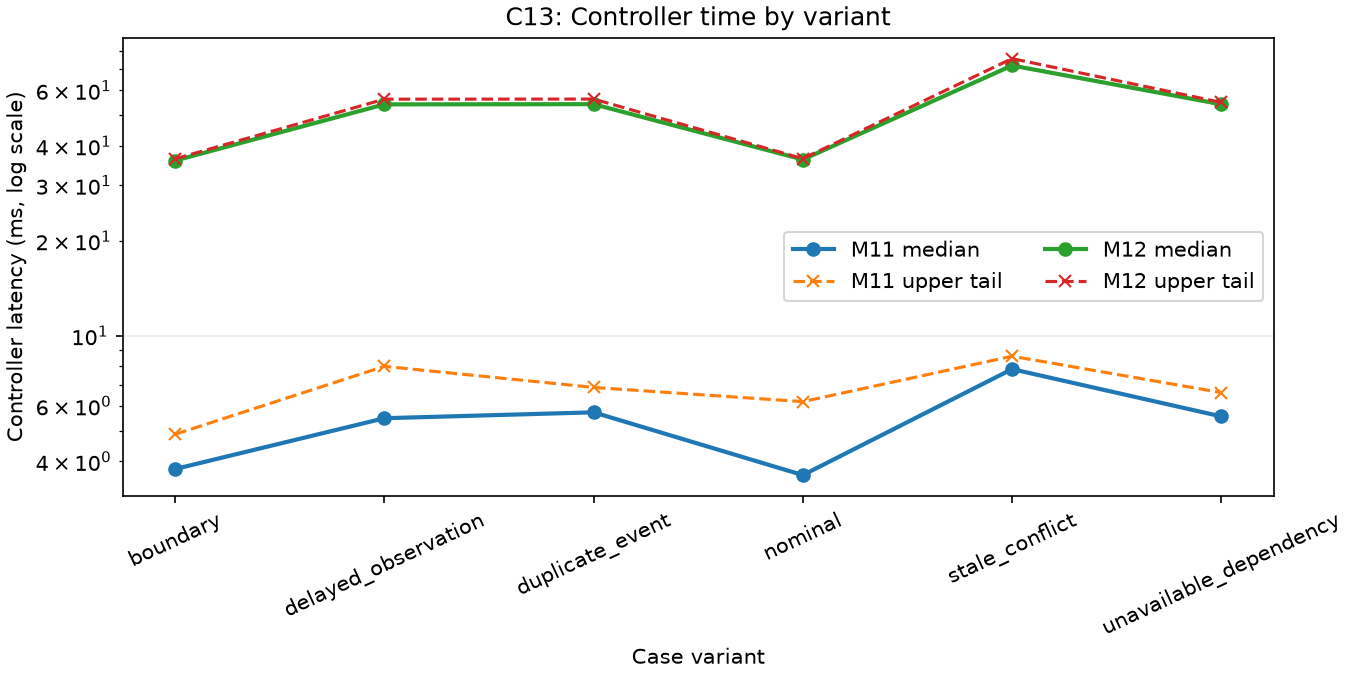

In [9]:
# Compare median and upper-tail controller time across all matched case variants.
variants = sorted({variant for _, variant in case_records})
methods_to_plot = selected_methods
fig, ax = plt.subplots(figsize=(9, 4.5), constrained_layout=True)
for method_id in methods_to_plot:
    p50, p95 = [], []
    for variant in variants:
        episodes = case_records.get((method_id, variant), [])
        values = sorted(float(e['metrics']['controller_ms']) for e in episodes)
        p50.append(values[(len(values) - 1) // 2] if values else float('nan'))
        p95.append(values[min(len(values) - 1, int(.95 * (len(values) - 1)))] if values else float('nan'))
    ax.plot(variants, p50, marker='o', linewidth=2, label=f'{method_id} median')
    ax.plot(variants, p95, marker='x', linestyle='--', label=f'{method_id} upper tail')
ax.set_yscale('log')
ax.set_ylabel('Controller latency (ms, log scale)')
ax.set_xlabel('Case variant')
ax.set_title(sample_case + ': Controller time by variant')
ax.tick_params(axis='x', rotation=25)
ax.grid(axis='y', alpha=.25)
ax.legend(ncol=2)
image_buffer = BytesIO()
fig.savefig(image_buffer, format='png', dpi=150)
display(Image(data=image_buffer.getvalue()))
image_buffer.close()
plt.close(fig)




Chart 2, lesson level 1, summarizes family-level controller latency alongside task completion for C13 in the planner delegation cost and paired task outcomes study. For chart 2 at level 1, the planner delegation cost and paired task outcomes denominator is the manifest-hash-verified C13 episode slice loaded above, and failed outcomes remain included. The designed C13 cases in chart 2 at level 1 for planner delegation cost and paired task outcomes cannot estimate real-world incident rates or performance on unseen software. Read chart 2 at level 1 alongside the planner delegation cost and paired task outcomes trace and verified postcondition before attributing an improvement to a controller.


## Results

**Answer:** The deliberation allocation example executes 2 policies, M11 and M12, on C13; C13 makes handoff allocation observable:

The gate fit used 228 states with seven positive labels and selected threshold 1.01, meaning it never delegated through that gate. M12's other trigger is separate. In the single-run deliberation allocation exercise on C13, report planner calls, latency and verified success; Within this one-case deliberation allocation run (C13), A configured LLM is not evidence of useful deliberation;

## Summary

C13 exposes the handoff path; a planner call alone is not evidence of benefit.




## References
- [JEV](https://typesafe.ai/blog/introducing-system-one-models-and-jev) - [DPT](https://aclanthology.org/2025.acl-long.206/) - [VOC](https://arxiv.org/abs/1711.06892) - [DEFER](https://proceedings.mlr.press/v119/mozannar20b.html) - DPT-Agent. Code and FSM control with asynchronous language-model reasoning. https://aclanthology.org/2025.acl-long.206/